# The decision replay: what the lift does to the loan book

The bought-vs-built AUC gap is small (0.769 internal-only to 0.794 combined). This notebook replays the actual approve-or-decline decision to show what that gap is worth in loans, not points. It reuses the exact out-of-fold predictions the study already saved (the same fixed model everywhere) and never re-tunes anything.

Every number the Medium post claims in its business-value section is computed here: the drop in approved defaults, the swap behind it, the scores-only comparison, and the losses prevented.

This is the **losses-prevented** view (one assumption: loss given default). Notebook 24 is the complementary **profit frontier** that additionally credits margin on the extra good loans and sweeps the economics; it reports a larger figure because it counts a second thing. Both are correct; this one is the more conservative.

In [1]:
import sys; sys.path.append("..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from src.data import INTERIM, RAW
from src.models import oof

runs = INTERIM / "runs"
p_int = pd.read_pickle(runs / "engineered_internal_only.pkl").rename("p_int")
p_comb = pd.read_pickle(runs / "engineered_combined.pkl").rename("p_comb")
app = pd.read_csv(RAW / "application_train.csv",
                  usecols=["SK_ID_CURR", "TARGET", "AMT_CREDIT", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]).set_index("SK_ID_CURR")

df = app.join(p_int).join(p_comb).dropna(subset=["p_int", "p_comb"])
y = df["TARGET"].to_numpy(); amt = df["AMT_CREDIT"].to_numpy(); default = y == 1
n = len(df); vol = amt.sum()
K, LGD = 0.90, 0.60
GRAY, ACCENT, REF, TXT = "#C9C9C9", "#3F7CAC", "#C0504D", "#404040"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 120})
print(f"{n:,} applicants | default rate {default.mean():.1%} | approve safest {K:.0%} | loss given default {LGD:.0%}")

307,511 applicants | default rate 8.1% | approve safest 90% | loss given default 60%


## Approve the safest 90%, count the defaults that slip through

Rank applicants by predicted risk under each model, approve the lowest-risk 90%, and tally how many approved loans actually defaulted. Better ranking means fewer bad loans on the book at the same approval rate.

In [2]:
def approved(p):
    m = np.zeros(n, bool); m[np.argsort(p)[:int(K * n)]] = True; return m

in_i, in_c = approved(df["p_int"].to_numpy()), approved(df["p_comb"].to_numpy())
bad_i, bad_c = int((in_i & default).sum()), int((in_c & default).sum())
print(f"approved defaults, internal-only : {bad_i:,}")
print(f"approved defaults, combined      : {bad_c:,}")
print(f"the external scores prevent        {bad_i - bad_c:,} defaults on the book")

approved defaults, internal-only : 16,159
approved defaults, combined      : 15,311
the external scores prevent        848 defaults on the book


## The swap behind the net gain

The net figure hides churn. Adding the scores reshuffles the book: it correctly removes some bad loans the internal-only model approved, but incorrectly lets others back in. The net is the difference.

In [3]:
caught = default & in_i & ~in_c
let_in = default & in_c & ~in_i
print(f"bad loans the scores CATCH  (removed) : {int(caught.sum()):,}")
print(f"bad loans the scores LET IN (added)   : {int(let_in.sum()):,}")
print(f"net fewer defaults                    : {int(caught.sum() - let_in.sum()):,}")

bad loans the scores CATCH  (removed) : 2,471
bad loans the scores LET IN (added)   : 1,623
net fewer defaults                    : 848


## The final test: what if we skipped the internal build and just bought the scores?

The same fixed model, trained only on the three purchased external scores, scored out-of-fold. If the scores were the foundation, this should be the best book. It is the worst.

In [4]:
def gbm():
    return lgb.LGBMClassifier(n_estimators=800, learning_rate=0.03, num_leaves=31, min_child_samples=50,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=2.0,
                              n_jobs=-1, verbose=-1)

p_scores = oof(gbm(), df[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]], df["TARGET"])
in_s = approved(p_scores)
bad_s = int((in_s & default).sum())
print(f"scores-only OOF AUC              : {roc_auc_score(y, p_scores):.4f}")
print(f"approved defaults, scores-only  : {bad_s:,}")
print(f"vs internal-only                : {bad_i:,}  ->  scores-only lets in {bad_s - bad_i:,} MORE")

scores-only OOF AUC              : 0.7202
approved defaults, scores-only  : 17,612
vs internal-only                : 16,159  ->  scores-only lets in 1,453 MORE


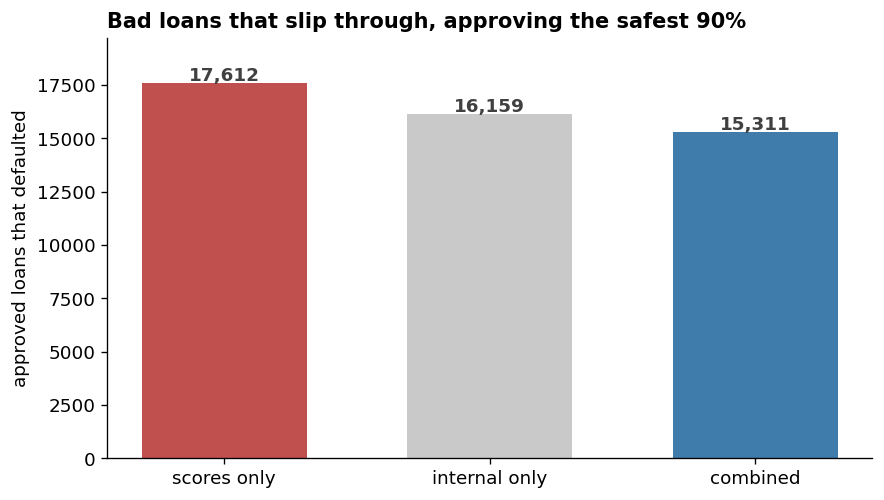

In [5]:
order = ["scores only", "internal only", "combined"]
counts = [bad_s, bad_i, bad_c]
cols = [REF, GRAY, ACCENT]
fig, ax = plt.subplots(figsize=(7.5, 4.3))
bars = ax.bar(order, counts, color=cols, width=0.62)
for b, c in zip(bars, counts):
    ax.text(b.get_x() + b.get_width() / 2, c + 90, f"{c:,}", ha="center", fontsize=11, color=TXT, fontweight="bold")
ax.set_ylabel("approved loans that defaulted")
ax.set_ylim(0, max(counts) * 1.12)
ax.set_title("Bad loans that slip through, approving the safest 90%", loc="left", fontweight="bold", fontsize=12.5)
plt.tight_layout(); plt.show()

## Losses prevented

Price the swap. A defaulted loan loses `LGD` of its value; the value of the scores is the loss avoided on the loans they remove, net of the loss added by the loans they let in. Expressed as a share of loan value it is currency-free, which turns it into a break-even price for the score.

In [6]:
net_loan = amt[caught].sum() - amt[let_in].sum()
loss_prevented = LGD * net_loan
per_applicant = loss_prevented / n
pct_of_loan = loss_prevented / vol * 100
med, top1 = np.median(amt), amt[amt >= np.quantile(amt, 0.99)].mean()
print(f"net defaulted loan value avoided : {net_loan:,.0f}")
print(f"losses prevented ({LGD:.0%} LGD)       : {loss_prevented:,.0f}")
print(f"per applicant (book-wide average): {per_applicant:,.2f}")
print(f"as a share of loan value         : {pct_of_loan:.3f}%\n")
print(f"BREAK-EVEN: buy the score when its price is below {pct_of_loan:.3f}% of the loan")
for label, L in [("a small 10,000 loan", 10_000), (f"the median loan ({med:,.0f})", med), (f"a top-1% loan ({top1:,.0f})", top1)]:
    print(f"  {pct_of_loan:.3f}% of {label:30s} = {pct_of_loan / 100 * L:,.0f}")

net defaulted loan value avoided : 487,576,215
losses prevented (60% LGD)       : 292,545,729
per applicant (book-wide average): 951.33
as a share of loan value         : 0.159%

BREAK-EVEN: buy the score when its price is below 0.159% of the loan
  0.159% of a small 10,000 loan            = 16
  0.159% of the median loan (513,531)      = 816
  0.159% of a top-1% loan (2,141,054)      = 3,400


## Bottom line

Adding the purchased scores prevents about 850 defaults on this book, the net of catching roughly 2,500 bad loans and letting roughly 1,600 back in. On their own the scores are the weakest of the three books. At a 60% loss given default that net is worth about 951 per applicant, near 0.16% of a typical loan, so the score earns its price wherever it costs less than that, and most where the loan is largest.